# Linear ridge regression example for the challenge Dyni Odontocete Click Classification, 10 species

In [9]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score
import time

In [10]:
# read data
X_train = np.load('./DOCC10_train/DOCC10_Xtrain.npy')
X_test = np.load('./DOCC10_test/DOCC10_Xtest.npy')
Y_train_df = pd.read_csv('./DOCC10_Ytrain.csv', index_col=0)


print('X train', X_train.shape, 'Y_train', Y_train_df.shape, 'X_test', X_test.shape)
Y_train_df.describe()

X train (113120, 8192) Y_train (113120, 1) X_test (20960, 8192)


,TARGET
count,113120
unique,10
top,UDA
freq,11312


In [11]:
train_vis = np.load('./DOCC10_test/DOCC10_Xtest.npy')
print(train_vis[0])
print(max(train_vis[5]))
print(min(train_vis[5]))


[-0.00607855 -0.00613767 -0.00614087 ...  0.0041538   0.00418604
  0.00417089]
0.009429932
-0.005493164


In [12]:
# encorde string labels with one-hot vectors
Y_tr_ = Y_train_df['TARGET'].values.reshape(-1, 1)
enc = OneHotEncoder()
enc.fit(Y_tr_)
Y_tr = enc.transform(Y_tr_).toarray()

In [13]:
# shuffle train set
perm = np.random.permutation(X_train.shape[0])
X = X_train[perm]
y = Y_tr[perm]
X.shape, y.shape

((113120, 8192), (113120, 10))

# Data inspection

In [14]:
from matplotlib import pyplot as plt

# Sorting by category

categories = {
    cat: X_train[(Y_train_df['TARGET'] == cat).values]
    for cat in sorted(Y_train_df['TARGET'].unique())
}

for cat, x in categories.items():
    print(cat, x.shape)

GG (11312, 8192)
GMA (11312, 8192)
LA (11312, 8192)
MB (11312, 8192)
ME (11312, 8192)
PM (11312, 8192)
SSP (11312, 8192)
UDA (11312, 8192)
UDB (11312, 8192)
ZC (11312, 8192)


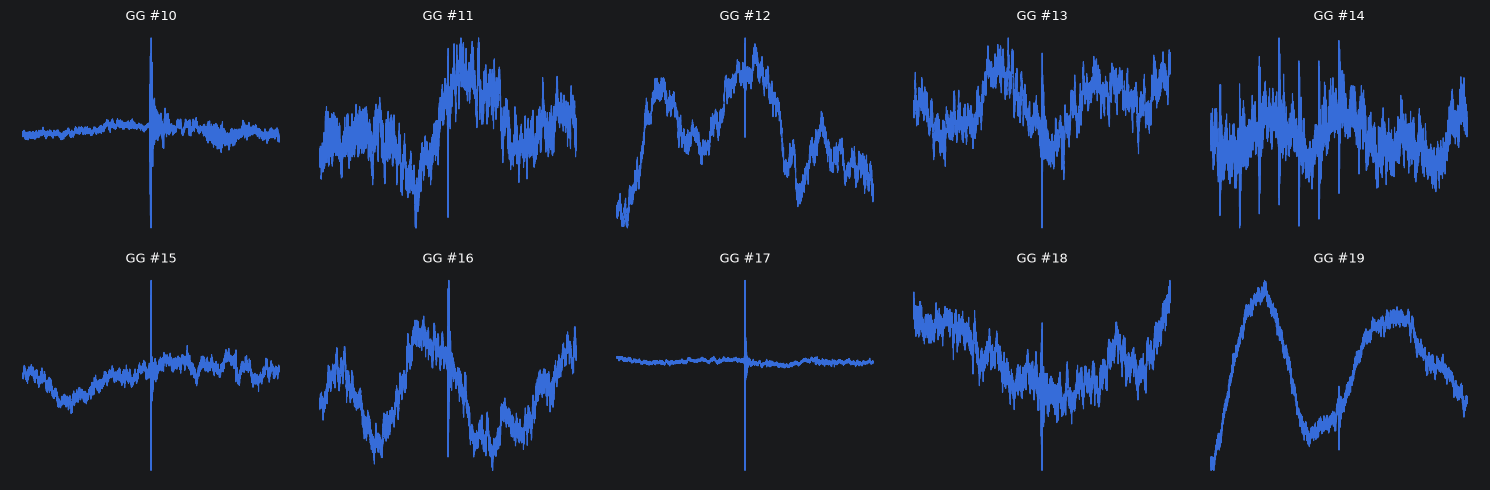

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5))
for ax, i in zip(axes.flat, range(10, 20)):
    ax.plot(categories['GG'][i], lw=0.8)
    ax.set_title(f'GG #{i}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

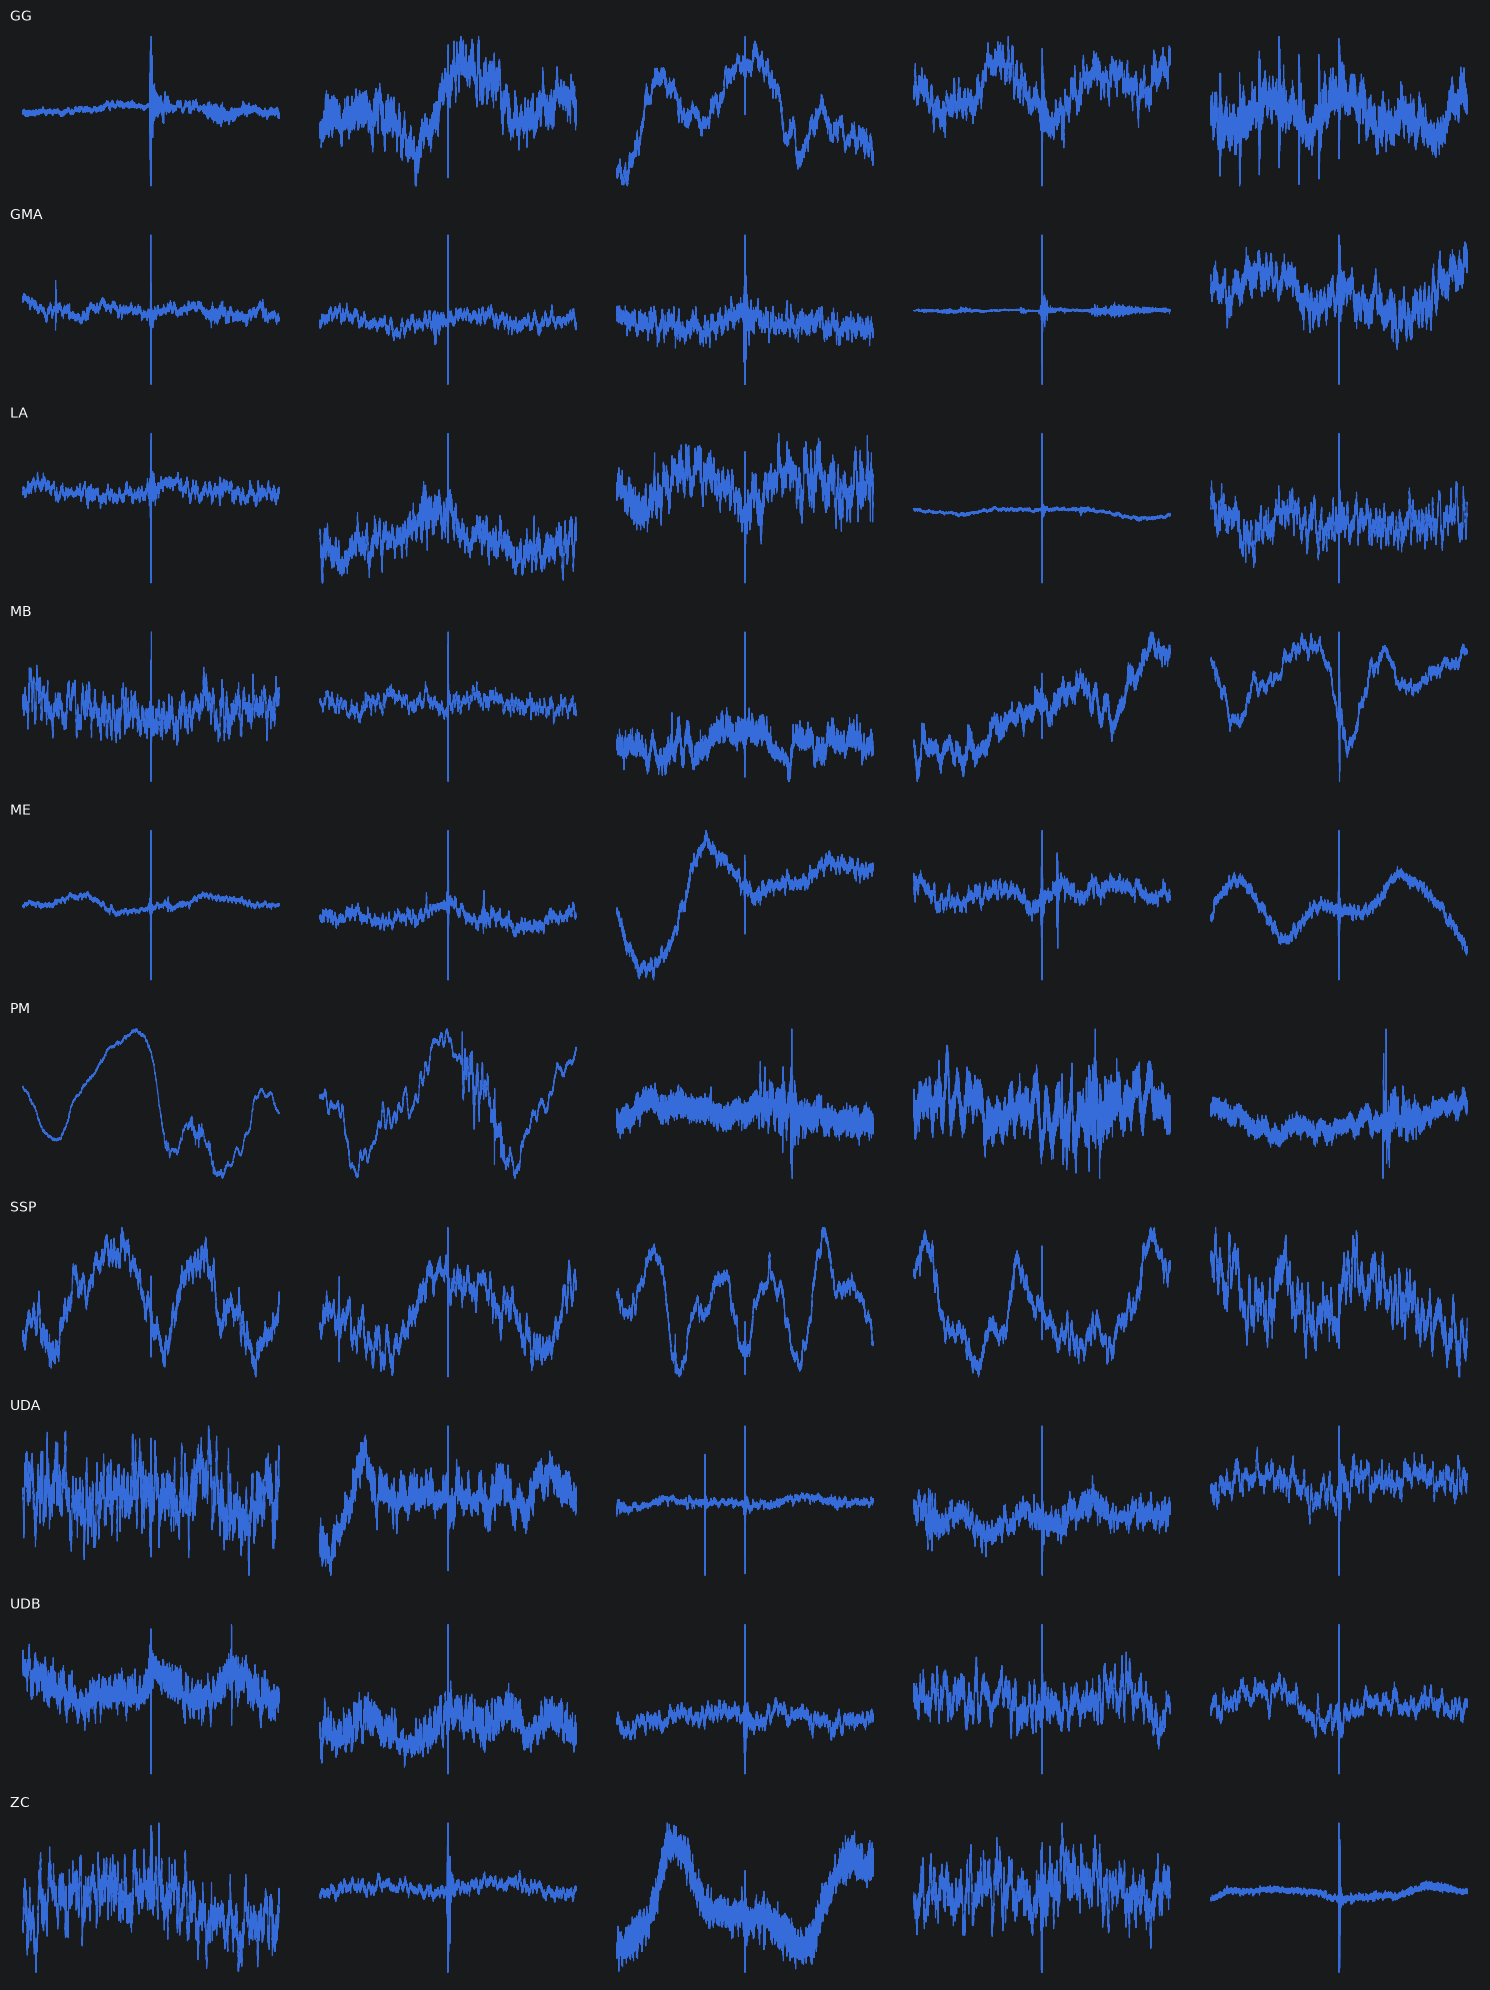

In [16]:
classes = list(categories.keys())
fig, axes = plt.subplots(len(classes), 5, figsize=(15, 2 * len(classes)))
for row, c in enumerate(classes):
    for col in range(5):
        ax = axes[row, col]
        ax.plot(categories[c][10 + col], lw=0.8)
        ax.axis('off')
    axes[row, 0].set_title(c, loc='left', fontsize=10)
plt.tight_layout()
plt.show()

In [17]:
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import uniform_filter1d

fs = 200_000
sos = butter(4, 5_000, btype='highpass', fs=fs, output='sos')   # cut < 5 kHz

def preprocess(X, half=256, batch=2000):
    out = np.empty((len(X), 2*half), dtype=np.float32)
    for i in range(0, len(X), batch):                 # batches: the full array is ~3.7 GB
        xb = sosfiltfilt(sos, X[i:i+batch], axis=1)
        env = uniform_filter1d(np.abs(hilbert(xb, axis=1)), 64, axis=1)  # smoothed envelope
        pk = env[:, half:-half].argmax(1) + half                         # click position
        idx = pk[:, None] + np.arange(-half, half)
        seg = np.take_along_axis(xb, idx, axis=1)
        seg /= np.abs(seg).max(1, keepdims=True) + 1e-9                  # amplitude norm
        out[i:i+batch] = seg
    return out

Xp_train = preprocess(X_train)
Xp_test  = preprocess(X_test)       # apply exactly the same steps to the test set
y_lab = Y_train_df['TARGET'].values

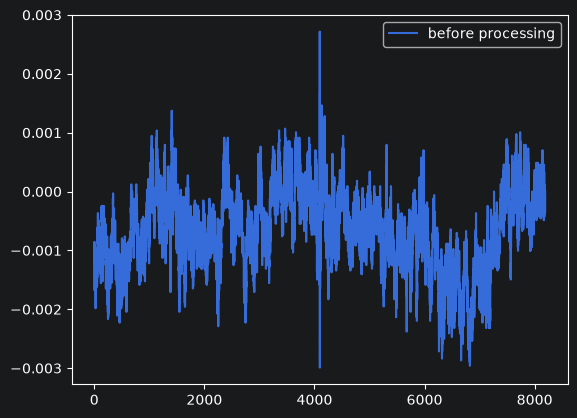

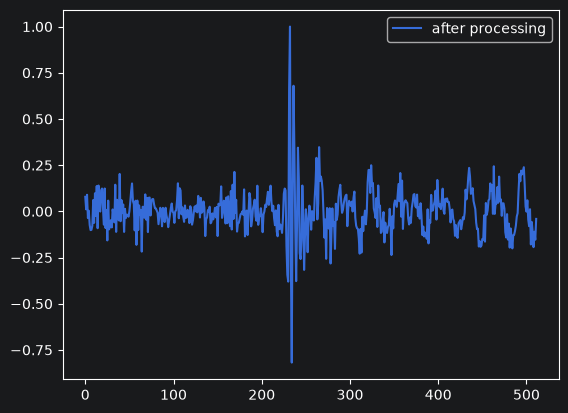

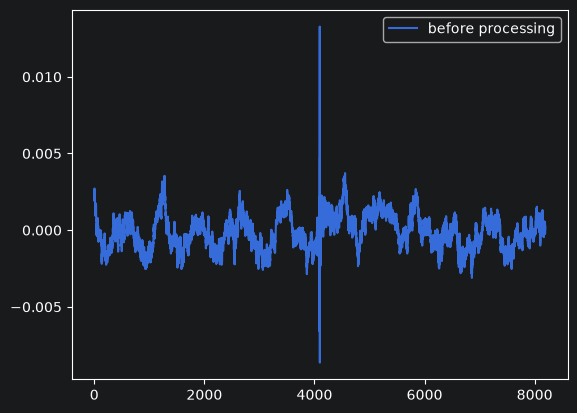

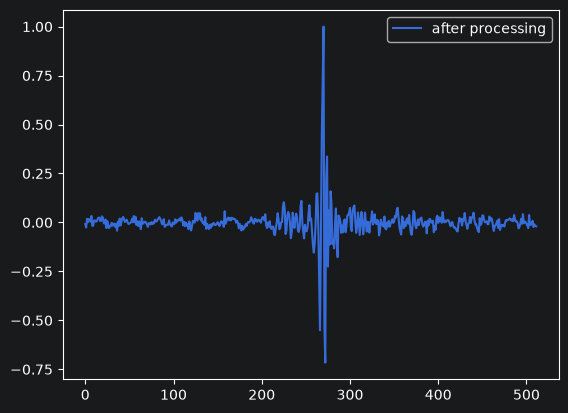

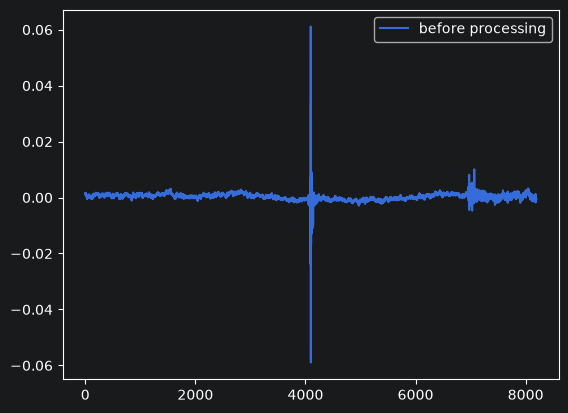

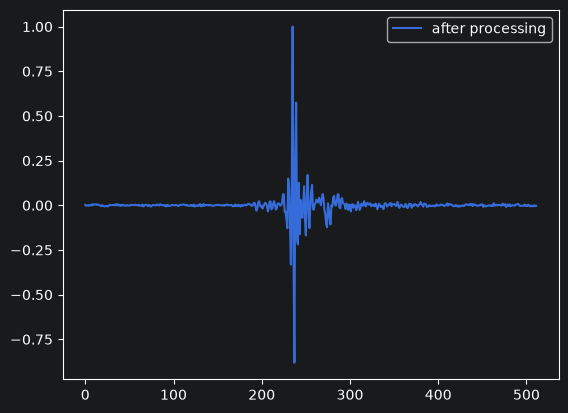

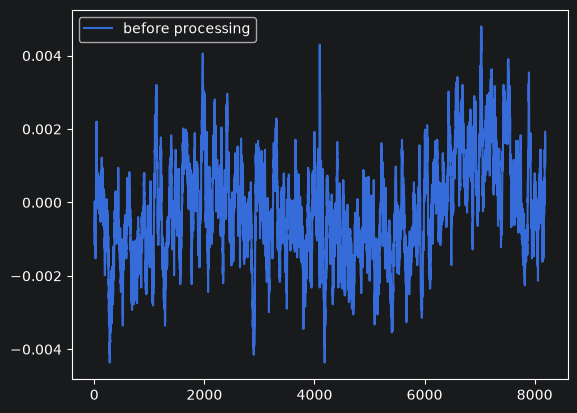

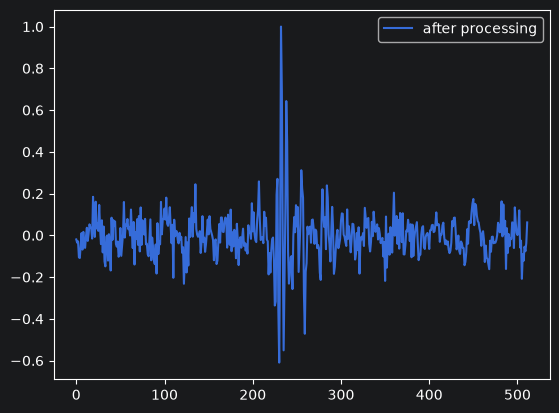

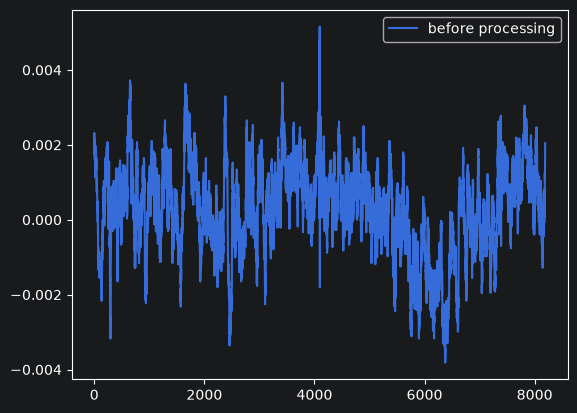

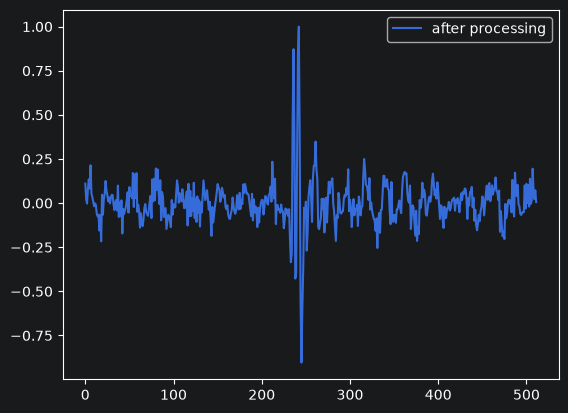

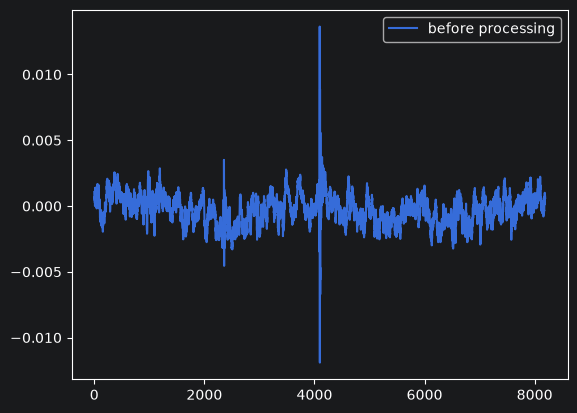

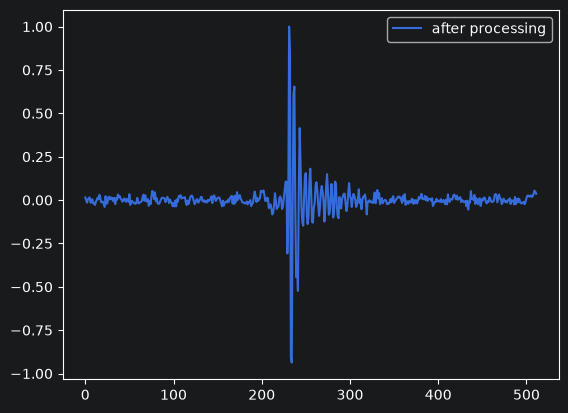

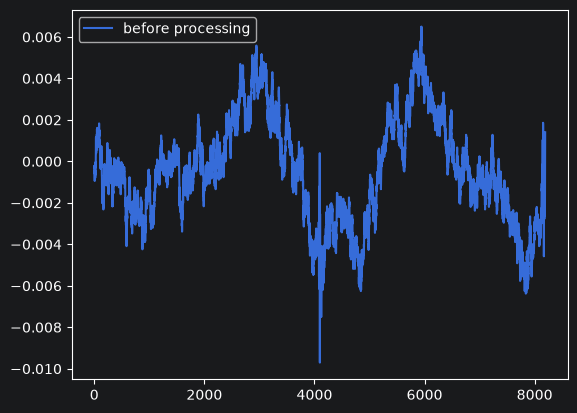

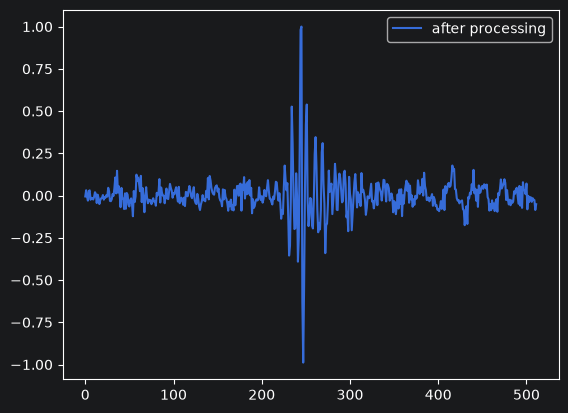

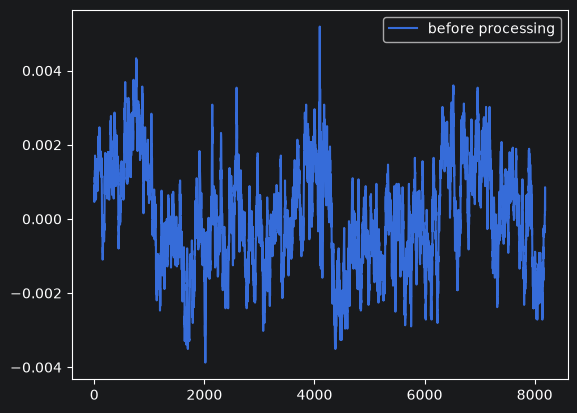

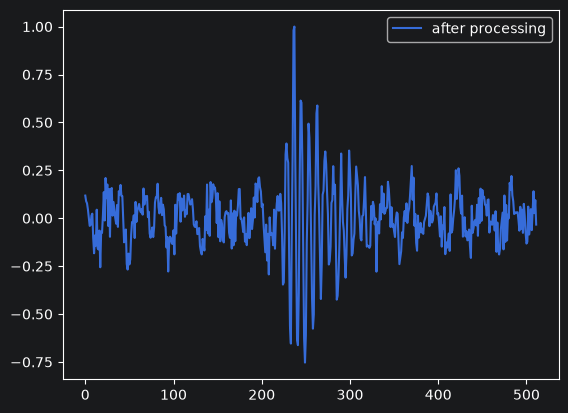

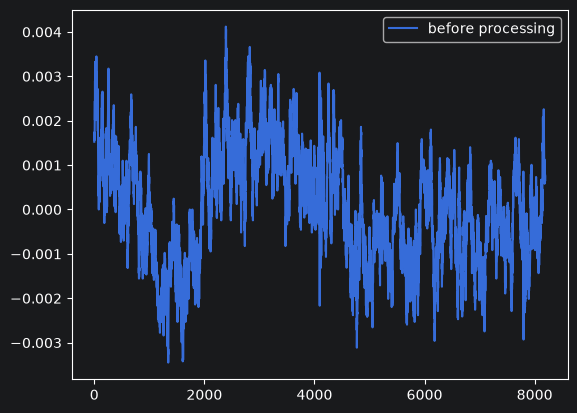

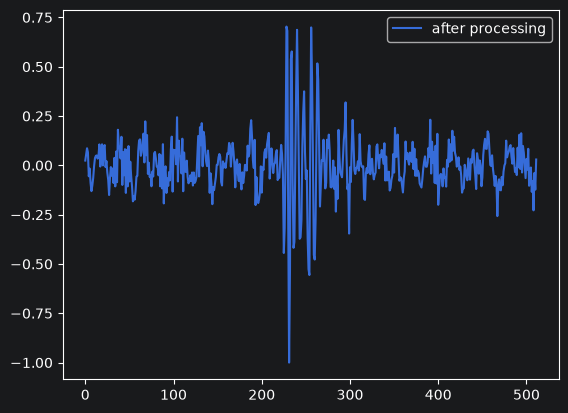

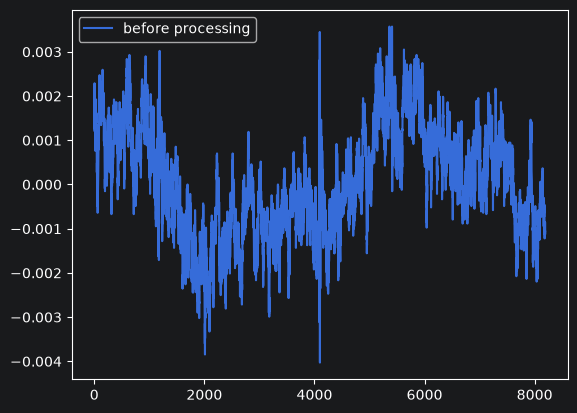

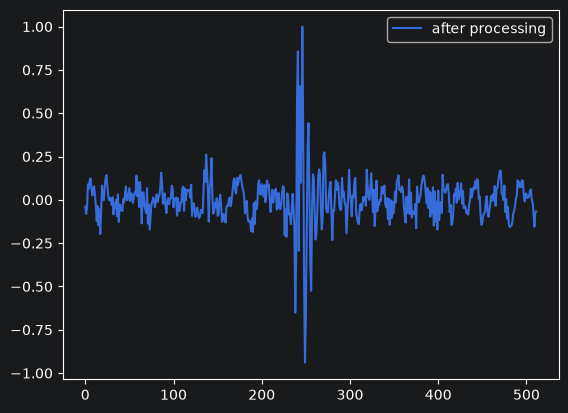

In [18]:
for i in range(10):
    # Comparaison
    plt.figure()
    plt.plot(X_train[i], label='before processing')
    plt.legend()
    plt.show()

    plt.figure()
    plt.plot(Xp_train[i], label='after processing')
    plt.legend()
    plt.show()

# Baseline (regression ridge)

In [19]:
# cross validate the ridge parameter alpha
alphas = 10.**(-np.arange(-5,5))
best_acc = 0
best_alpha = -1

for alpha in alphas:
    t0 = time.time()
    reg = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    y_pred = cross_val_predict(reg, X=X, y=y, cv=4)
    acc = accuracy_score(np.argmax(y, axis=1), np.argmax(y_pred, axis=1))
    if acc > best_acc:
        best_acc, best_alpha = acc, alpha
    t = (time.time() - t0) / 60
    print(f'alpha={alpha} acc={acc}, t = {t:.1f} min')

MemoryError: Unable to allocate 2.59 GiB for an array with shape (84840, 8192) and data type float32

In [ ]:
# fit regressor on the whole train db
reg = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
reg.fit(X, y)

In [ ]:
# save predictions to csv for submission
y_test_pred = reg.predict(X_test.astype('float32'))
y_test_pred = (y_test_pred == y_test_pred.max(axis=1, keepdims=True)).astype(float)
y_test_pred = enc.inverse_transform(y_test_pred)
Y_test_pred_df = pd.DataFrame(data=y_test_pred, index=np.arange(y_test_pred.shape[0]), columns=['TARGET'])
Y_test_pred_df.to_csv('./DOCC10_Ytest_pred_linear.csv', index_label='ID')